# Week 5 | Transfer Learning for Scene Classification
**Project 2: Deep Learning Applications | Individual**  
Introduction to Applied AI | Department of Electronics | Platform: Kaggle Notebook (GPU T4)

---

## Objective
Build a first deep-learning image classifier and understand every number it produces. Using the **Intel Image Classification** dataset (6 scene classes), this notebook:

1. treats an image as a tensor and reproduces a convolution and parameter counts by hand,
2. builds train / validation / test pipelines with augmentation on the training set only,
3. trains a pretrained **ResNet-18** with **feature extraction** (3,078 trainable parameters) and then **fine-tunes** the last block (`layer4`) with two learning rates,
4. evaluates the model **once** on the test set and studies its errors.

## Results at a Glance
| Item | Value |
|---|---|
| Dataset split | 11,929 train / 2,105 validation / 3,000 test |
| Feature extraction (3,078 trainable params), best val. accuracy | **0.901** |
| Fine-tuning `layer4` (8,396,806 trainable params), best val. accuracy | **0.931** (+3.04 points) |
| **Test accuracy (used once)** | **0.936** |
| Weakest class by recall | glacier (0.870), then buildings (0.908) |
| Most confused pair | glacier ↔ mountain (57 + 31 = 88 errors) |

---
# Part 1: The Data, and an Image as Numbers
## Task 1.1: Imports, GPU check, and class counts
Imports, reproducibility seeds (`42`), device selection, and the number of images per class in the training and test folders.

In [1]:
# ===== PART 1 | Task 1.1: Imports, GPU check, class counts =====
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
tot_tr, tot_te = 0, 0
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    tot_tr += n_tr; tot_te += n_te
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')
print('TOTAL train', tot_tr, 'test', tot_te)

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501
TOTAL train 14034 test 3000


**Output interpretation**

- The first line prints `Device: cuda`, so the GPU accelerator is active and training will take about a minute per epoch rather than hours.
- The Intel dataset contains **14,034 training** and **3,000 test** images across 6 classes.
- The classes are reasonably balanced: the training counts range from 2,191 (buildings) to 2,512 (mountain), so the largest class is only about 15% bigger than the smallest. Plain accuracy is therefore a fair headline metric, although per-class recall is still reported later.

## Task 1.2: Look at the images, then at the numbers
Two sample images per class are displayed, followed by the raw pixel array of the last image loaded.

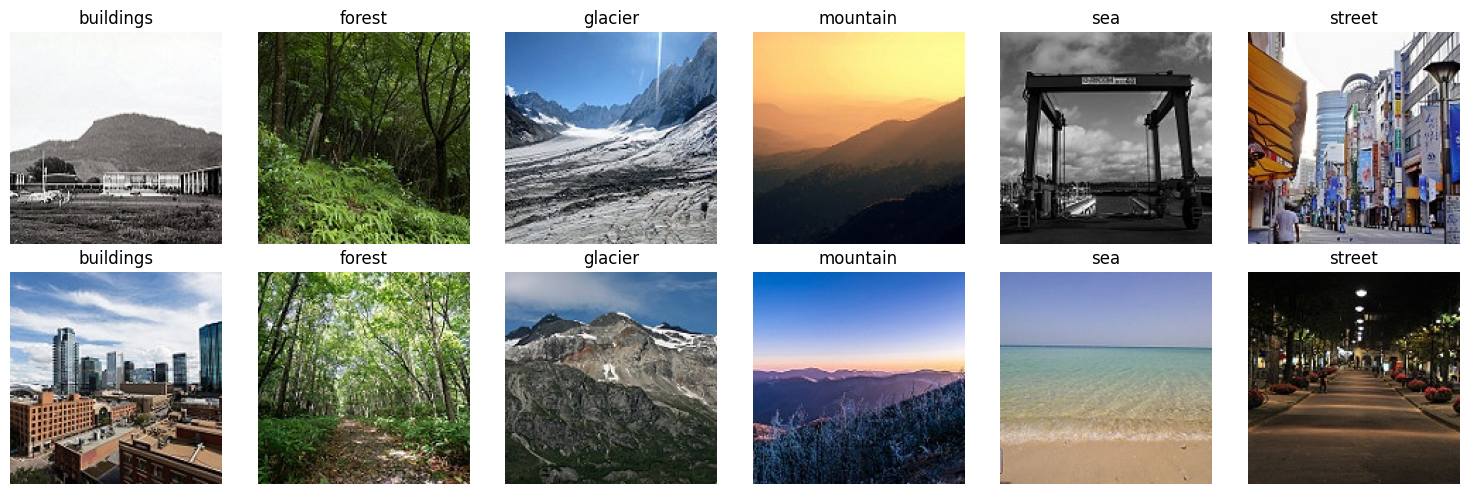

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [2]:
# ===== PART 1 | Task 1.2: Look at the images, then at the numbers =====
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### Write it: Part 1

**Which classes look most similar?** From the sample grid, **glacier and mountain** look the most alike: both show rocky, snow-capped peaks and similar blue-white skies (the second glacier image is almost indistinguishable from a mountain photo). **Buildings and street** are the second most similar pair, because both contain man-made structures. 

**Prediction (recorded before training):** the model will confuse **glacier ↔ mountain** most. This is checked in Part 6.

**Image facts (last image loaded, a night-time street scene):**

| Property | Value |
|---|---|
| Shape (H, W, C) | `(150, 150, 3)` |
| Data type | `uint8` |
| Value range | 0 to 255 |
| Numbers per image | 150 × 150 × 3 = **67,500** |

The top-left 3×3 patch of the red channel contains very small values (3 to 8) because that corner of the photo is nearly black. This confirms that an image is just a grid of integers where 0 is black and 255 is white.

---
# Part 2: Convolution and Parameters by Hand
## Task 2.1: Reproduce the lecture's convolution
A 5×5 image with a vertical edge between columns 2 and 3 is convolved with the kernel `[-1, 0, 1]` (applied to all three rows), then the same kernel is applied to a real grayscale photo.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


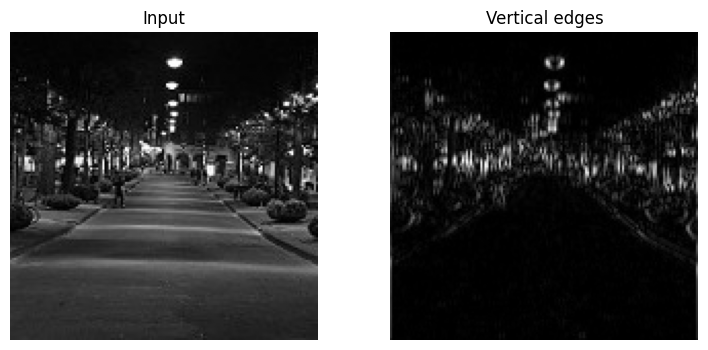

In [3]:
# ===== PART 2 | Task 2.1: Reproduce the lecture's convolution =====
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())   # expect three rows of [30, 30, 0]

# Same kernel on a real photo (grayscale)
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

**Output interpretation**

- `F.conv2d` returns three rows of `[30, 30, 0]`, which **exactly matches the hand calculation** from the lecture (slide 17). For the top-left position: each row gives (−1)(0) + (0)(0) + (1)(10) = 10, and three rows give 10 + 10 + 10 = **30**.
- The output is non-zero (30) wherever the window covers the 0 → 10 jump and **zero where the image is flat** (the right-most column). The kernel therefore responds only to a vertical edge.
- On the real night-street photo, the edge map is dark in smooth regions (road surface, sky) and bright along **vertical structures**: street lamps, tree trunks, and building edges. The same 3×3 kernel, reused at every position, detects vertical edges across the whole image. A CNN learns many such kernels automatically by backpropagation instead of having them hand-designed.

## Task 2.2: Why convolutions, in numbers
Parameter counts of a 3×3 convolution versus a dense layer, and output shapes for different strides and pooling.

In [4]:
# ===== PART 2 | Task 2.2: Why convolutions, in numbers =====
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64  : {count(conv):,} parameters')    # (3*3*3+1)*64
print(f'Dense 67,500 -> 512: {count(dense):,} parameters')
print(f'Dense / Conv ratio : {count(dense) / count(conv):,.0f}x')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    cc = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(cc(t).shape)}')
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64  : 1,792 parameters
Dense 67,500 -> 512: 34,560,512 parameters
Dense / Conv ratio : 19,286x
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### Write it: Part 2

**Parameter arithmetic**

- Convolution (3×3, 3 → 64 channels): (K × K × C_in + 1) × C_out = (3 × 3 × 3 + 1) × 64 = 28 × 64 = **1,792**
- Dense layer (67,500 → 512): 67,500 × 512 weights + 512 biases = 34,560,000 + 512 = **34,560,512**

**Ratio:** 34,560,512 / 1,792 ≈ **19,286 times** more parameters for the dense layer.

**Output sizes verified with (W − K + 2P) / S + 1:**

| Case | Calculation | Result |
|---|---|---|
| Stride 1 | (224 − 3 + 2) / 1 + 1 | 224 → `(1, 64, 224, 224)` |
| Stride 2 | (224 − 3 + 2) / 2 + 1 = 112 (rounded down) | `(1, 64, 112, 112)` |
| 2×2 max pool | 224 / 2 | `(1, 3, 112, 112)` (channels unchanged) |

All printed values match the formulas. The convolution's size (1,792) does **not** depend on the image size, whereas the dense layer's size grows with every pixel.

**Why weight sharing helps recognise the same object in different places:** the same filter (the same weights) is slid over every position, so a pattern such as a tree trunk produces the same response wherever it appears, and the network learns it once instead of separately for each location. A dense layer has a separate weight for every pixel position, so it would have to relearn the same object at each location.

---
# Part 3: Transforms and Data Loaders
Pretrained ResNet expects 224 × 224 inputs normalised with the **ImageNet mean and standard deviation**. Augmentation (random crop, horizontal flip, mild colour jitter) is applied to the **training images only**. Because a PyTorch dataset holds one transform, the training folder is opened twice (augmented view and clean view) and both are split with the same random indices, so the validation set stays clean and never overlaps with the training set.

In [5]:
# ===== PART 3: Transforms and Data Loaders =====
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


**Why a validation set when a test set exists?** Validation accuracy is used to choose the best epoch and to compare feature extraction with fine-tuning. The test set takes no part in any such choice, so the final test score remains an unbiased estimate.

### Write it: Part 3

| Split | Images | Source |
|---|---|---|
| Train | **11,929** | 85% of `seg_train` (augmented view) |
| Validation | **2,105** | 15% of `seg_train` (clean view) |
| Test | **3,000** | `seg_test` (clean view) |

The train and validation counts sum to 14,034, the full training folder, so no image is lost or shared between the two.

**An augmentation that would be wrong for this dataset:** `RandomRotation(90)` or a vertical flip. Scene photos have a fixed gravity-defined layout (sky above, ground or water below). A sea turned upside down, or a mountain with the sky at the bottom, is not a realistic sample of any class, so the model would learn from images it will never see in practice.

**An augmentation that would be wrong for handwritten digits:** `RandomHorizontalFlip` (or a 180° rotation). A mirrored digit is not a valid digit (a flipped 2 or 5 looks like a different symbol), and rotating a 6 by 180° turns it into a 9, which would corrupt the labels.

---
# Part 4: The Training Loop and Feature Extraction
## Task 4.1: A reusable training loop
`run_epoch` performs one pass over a loader, and `fit` repeats it for several epochs while keeping the weights from the best validation epoch.

In [7]:
# ===== PART 4 | Task 4.1: Reusable training loop =====
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

**Explanation (no output expected)**

The four boxes of the training loop (slide 12) appear in `run_epoch`:

| Step | Code | Role |
|---|---|---|
| Forward | `logits = model(xb)` | compute raw class scores |
| Loss | `F.cross_entropy(logits, yb)` | softmax + negative log-likelihood (receives raw logits, so softmax is **not** applied twice) |
| Backward | `loss.backward()` | backpropagation computes all gradients |
| Step | `optimizer.step()` | Adam updates the weights |

`optimizer.zero_grad()` clears the gradients every batch because PyTorch accumulates them. `model.train(training)` switches the model between training and evaluation behaviour, and `torch.set_grad_enabled(training)` avoids gradient computation during validation. `fit` stores a copy of the weights whenever validation accuracy improves and reloads the best copy at the end.

## Task 4.2: Freeze the body, train a new head
All pretrained ResNet-18 weights are frozen, the 1,000-class head is replaced by a new `Linear(512, 6)` layer, and only this head is trained for 3 epochs with Adam (`lr = 1e-3`).

In [8]:
# ===== PART 4 | Task 4.2: Freeze the body, train a new head =====
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                                   # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))      # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters '
      f'({100 * trainable / count(model):.3f}%)')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best_fe = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best_fe:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


Trainable 3,078 of 11,179,590 parameters (0.028%)
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (256s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (37s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (35s)
Best validation accuracy, feature extraction: 0.901


### Write it: Part 4

**Trainable parameters:** 3,078 of 11,179,590 (**0.028%**) = 512 × 6 weights + 6 biases, as predicted.

**Validation accuracy after each epoch (feature extraction):**

| Epoch | Train loss | Train acc | Val loss | Val acc |
|---|---|---|---|---|
| 1 | 0.588 | 0.809 | 0.327 | 0.894 |
| 2 | 0.326 | 0.890 | 0.290 | 0.899 |
| 3 | 0.299 | 0.895 | 0.276 | **0.901** |

The best validation accuracy is **0.901**. Both losses fall every epoch, so the head is still learning and there is no overfitting yet. (The first epoch took 256 s mainly because of the one-time weight download and GPU/data-loader warm-up; later epochs took about 35 to 37 s.)

**Why is high accuracy possible while training only 0.03% of the parameters?** ResNet-18 was pretrained on 1.2 million ImageNet photos, and its early and middle layers already encode general visual features: edges and colour blobs in layer 1, textures in layers 2 to 3, and object parts in layers 4 to 5 (feature hierarchy, slide 20). These features are useful for almost any photograph, including forests, seas and streets. The 512 numbers produced by global average pooling already describe the scene well, so the new head only has to learn a linear mapping from 512 features to 6 classes.

---
# Part 5: Fine-Tuning and Learning Curves
## Task 5.1: Unfreeze `layer4` with two learning rates
The last residual block (`layer4`) is unfrozen and trained for 3 more epochs. It receives a gentle learning rate (`1e-4`) because its weights are already good, while the new head keeps the larger rate (`1e-3`).

In [9]:
# ===== PART 5 | Task 5.1: Fine-tune layer4 with two learning rates =====
for p in model.layer4.parameters():
    p.requires_grad = True                                    # unfreeze last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},        # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])           # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best_ft = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best_ft:.3f}')
print(f'Improvement over feature extraction: {100 * (best_ft - best_fe):+.2f} points')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.905 | val loss 0.226 acc 0.927 (38s)
epoch 2: train loss 0.170 acc 0.937 | val loss 0.203 acc 0.931 (38s)
epoch 3: train loss 0.124 acc 0.955 | val loss 0.217 acc 0.927 (37s)
Best validation accuracy, fine-tuned: 0.931
Improvement over feature extraction: +3.04 points


**Output interpretation**

- Trainable parameters rise from 3,078 to **8,396,806** (about 8.4 million), which matches the lecture: `layer4` holds roughly three quarters of all ResNet-18 parameters.
- Validation accuracy improves immediately in the first fine-tuning epoch (0.901 → 0.927) and peaks at **0.931** in epoch 5 (the second fine-tuning epoch), an improvement of **+3.04 points** over feature extraction.
- In the third fine-tuning epoch (epoch 6) validation loss rises slightly (0.203 → 0.217) and accuracy drops to 0.927, so `fit()` correctly restores the weights from the best epoch.

## Task 5.2: Plot the learning curves
Loss and accuracy for the training and validation sets across all 6 epochs; the dashed line marks where fine-tuning starts.

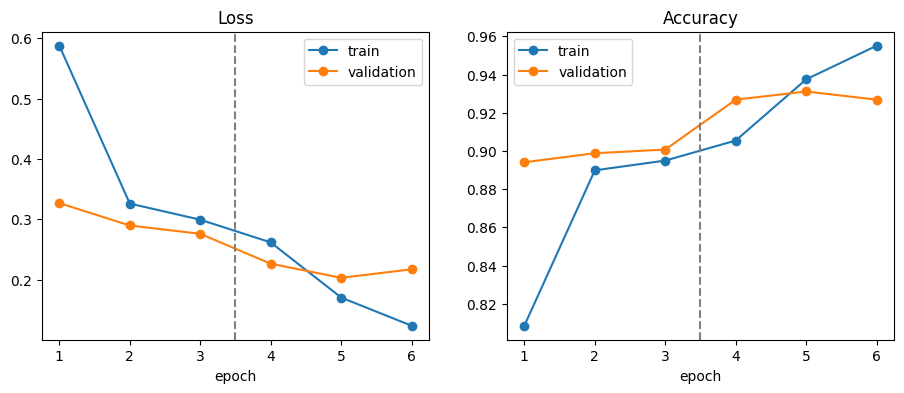

epoch | train_loss val_loss train_acc val_acc
    1 | 0.588      0.327    0.809     0.894
    2 | 0.326      0.290    0.890     0.899
    3 | 0.299      0.276    0.895     0.901
    4 | 0.262      0.226    0.905     0.927
    5 | 0.170      0.203    0.937     0.931
    6 | 0.124      0.217    0.955     0.927


In [10]:
# ===== PART 5 | Task 5.2: Learning curves =====
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')     # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

print('epoch | train_loss val_loss train_acc val_acc')
for i, r in enumerate(h, 1):
    print(f'{i:5d} | {r[0]:.3f}      {r[1]:.3f}    {r[2]:.3f}     {r[3]:.3f}')

### Write it: Part 5

**Did fine-tuning help?** Yes. Best validation accuracy rose from **0.901 (feature extraction)** to **0.931 (fine-tuning)**, a gain of **+3.04 percentage points**. Adapting the high-level features in `layer4` to scene classification gave the model more useful features than ImageNet's original ones.

**What the curves show**

| Phase | Epochs | Observation |
|---|---|---|
| Feature extraction | 1 to 3 | Train loss 0.588 → 0.299 and validation loss 0.327 → 0.276: both fall, so the head is learning. |
| Fine-tuning begins | 4 | Both losses drop again (train 0.262, val 0.226) because the adapted features help. |
| Late fine-tuning | 5 to 6 | Train loss keeps falling (0.170 → 0.124) while validation loss stops improving (0.203 → 0.217). |

**Is there overfitting?** There is an **early sign** at epoch 6: training loss and accuracy continue to improve (accuracy 0.955) while validation loss rises and validation accuracy falls slightly (0.931 → 0.927). The gap between training and validation performance is beginning to open, which is the signature of overfitting. Keeping the best validation epoch (epoch 5) and stopping at three fine-tuning epochs is therefore appropriate; more epochs would likely hurt unless more regularisation (weight decay, dropout) were added.

**Why training accuracy can be LOWER than validation accuracy:** in epochs 1 to 4 the training accuracy (0.809 to 0.905) is below the validation accuracy (0.894 to 0.927). The reasons are: (1) training images are **augmented** (random crops, flips, colour jitter), which makes them deliberately harder than the clean validation images; (2) training accuracy is **averaged over the whole epoch**, including batches seen while the weights were still poor, whereas validation is measured with the weights at the end of the epoch. The curves cross in epoch 5 once the model has adapted enough.

---
# Part 6: Test Once, Then Study the Errors
## Task 6.1: Test-set evaluation
The model (with the best validation weights) is evaluated on the 3,000 test images **a single time**. The cell reports accuracy, a per-class classification report, the confusion matrix, per-class recall, and the most frequent confusions.

Test accuracy: 0.936
              precision    recall  f1-score   support

   buildings      0.954     0.908     0.931       437
      forest      0.996     0.987     0.992       474
     glacier      0.920     0.870     0.894       553
    mountain      0.883     0.920     0.901       525
         sea      0.947     0.980     0.963       510
      street      0.930     0.958     0.944       501

    accuracy                          0.936      3000
   macro avg      0.938     0.937     0.937      3000
weighted avg      0.937     0.936     0.936      3000



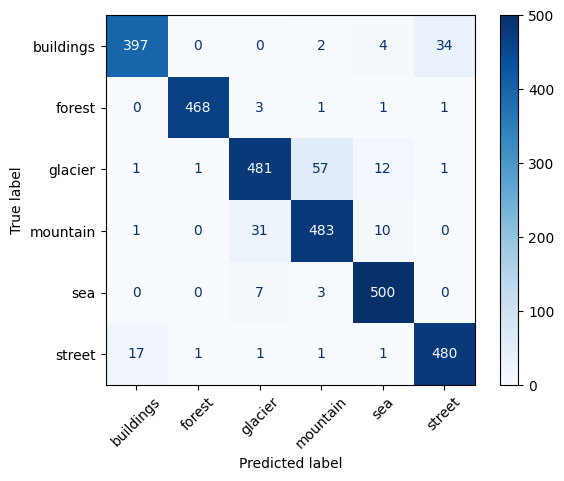

Confusion matrix (row=true, col=pred):
[[397   0   0   2   4  34]
 [  0 468   3   1   1   1]
 [  1   1 481  57  12   1]
 [  1   0  31 483  10   0]
 [  0   0   7   3 500   0]
 [ 17   1   1   1   1 480]]

Recall per class (weakest first):
  glacier    0.870
  buildings  0.908
  mountain   0.920
  street     0.958
  sea        0.980
  forest     0.987

Top 5 confusions (count, true -> predicted):
   57  glacier -> mountain
   34  buildings -> street
   31  mountain -> glacier
   17  street -> buildings
   12  glacier -> sea


In [11]:
# ===== PART 6 | Task 6.1: Test-set evaluation (run ONCE) =====
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

# Extra: raw matrix, per-class recall, most confused pairs (for the write-up)
print('Confusion matrix (row=true, col=pred):')
print(cm)
recall = cm.diagonal() / cm.sum(1)
print('\nRecall per class (weakest first):')
for i in np.argsort(recall):
    print(f'  {classes[i]:10s} {recall[i]:.3f}')
pairs = [(cm[i, j], classes[i], classes[j])
         for i in range(len(classes)) for j in range(len(classes)) if i != j]
print('\nTop 5 confusions (count, true -> predicted):')
for n_, a_, b_ in sorted(pairs, reverse=True)[:5]:
    print(f'  {n_:3d}  {a_} -> {b_}')

**Output interpretation**

- **Test accuracy = 0.936** (2,809 of 3,000 correct, 191 errors). This is very close to the validation accuracy of 0.931, which shows that the model selection did not overfit the validation set and that the result generalises.
- **Best classes:** forest (recall 0.987, precision 0.996) and sea (recall 0.980). These have distinctive colours and textures (green foliage, blue water).
- **Weakest classes by recall:** **glacier (0.870)** and **buildings (0.908)**. The lowest precision belongs to **mountain (0.883)**, because many glacier images are predicted as mountain.
- **Top confusions (true → predicted):** glacier → mountain (**57**), buildings → street (**34**), mountain → glacier (**31**), street → buildings (**17**), glacier → sea (12).
- The two largest error groups are symmetric pairs: **glacier ↔ mountain = 57 + 31 = 88 errors** (46% of all errors) and **buildings ↔ street = 34 + 17 = 51 errors**. Together these two pairs account for 139 of the 191 errors (about 73%).

## Task 6.2: Error gallery
The first eight misclassified test images with their true label, predicted label, and softmax confidence.

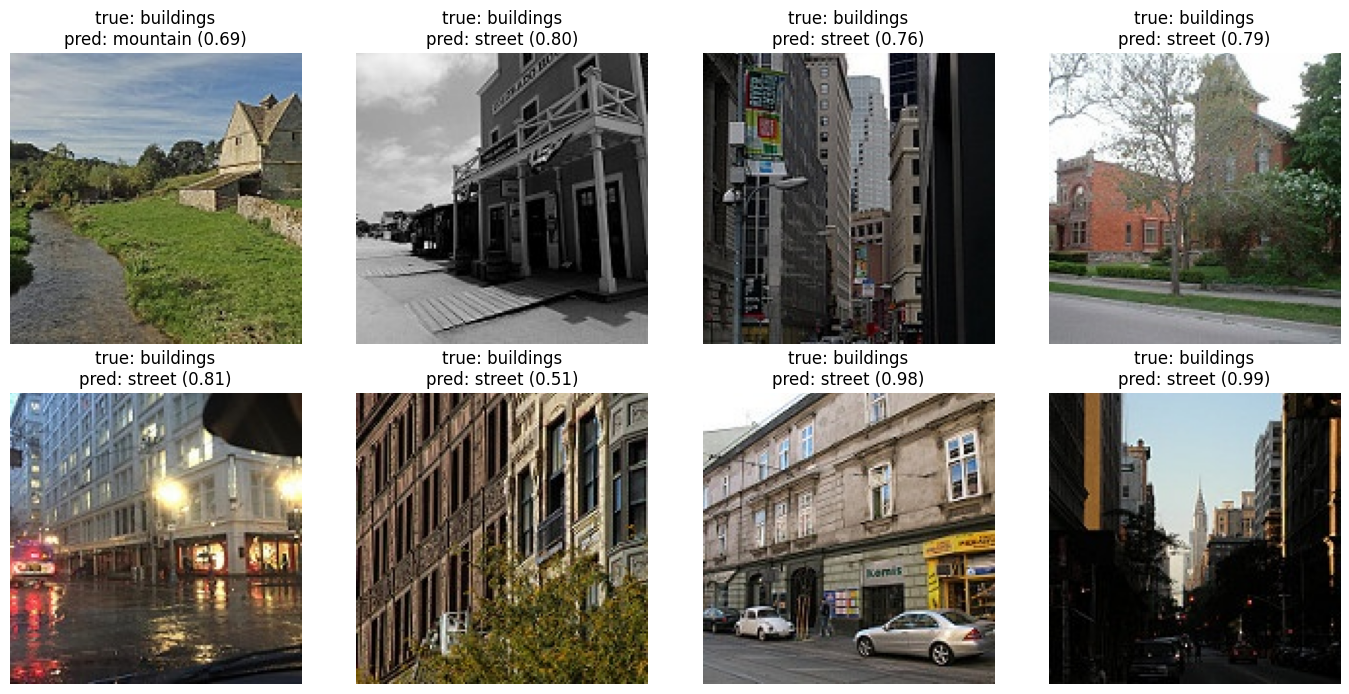

In [12]:
# ===== PART 6 | Task 6.2: Error gallery =====
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

**Note on the gallery:** the test set is ordered by class folder, so the first eight errors all come from the *buildings* class. The gallery therefore illustrates the buildings → street confusion (7 of 8 images) but does not show the largest confusion (glacier → mountain). Its content is analysed in the Write-it cell below.

## Task 6.3: Inside one prediction
The logits and softmax probabilities for the first test image, for comparison with the hand-computed softmax table from the lecture (slide 10).

In [13]:
# ===== PART 6 | Task 6.3: Inside one prediction =====
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')
print('Sum of probabilities:', round(p.sum().item(), 4))

True class: buildings
buildings  logit   8.04   probability 1.000
forest     logit  -9.42   probability 0.000
glacier    logit  -4.63   probability 0.000
mountain   logit  -5.04   probability 0.000
sea        logit  -4.76   probability 0.000
street     logit  -3.45   probability 0.000
Sum of probabilities: 1.0


### Write it: Part 6

**Test accuracy:** **0.936** (2,809 / 3,000).

**Two weakest classes by recall:** **glacier (0.870)** and **buildings (0.908)**.

**Most confused pair:** **glacier ↔ mountain** (57 glacier images predicted as mountain and 31 mountain images predicted as glacier, 88 in total). **My prediction from Task 1.2 was correct**: glacier and mountain look alike by eye, and the model confuses them most.

**Error-gallery analysis** (first 8 test errors, all with true class *buildings*):

| # | True → Predicted (confidence) | Verdict | Reasoning |
|---|---|---|---|
| 1 | buildings → mountain (0.69) | **Genuinely ambiguous** | A stone house sits small on a hillside beside a stream; the landscape dominates the frame, so "mountain/countryside" is understandable. |
| 2 | buildings → street (0.80) | **Genuinely ambiguous** | Black-and-white storefront with a boardwalk and road: it is both a building and a street scene. |
| 3 | buildings → street (0.76) | **Genuinely ambiguous** | A street-level view between tall buildings with signs and lamp posts; "street" is a reasonable label. |
| 4 | buildings → street (0.79) | **Model wrong** | A large brick house is clearly the main subject, although a road runs across the foreground. |
| 5 | buildings → street (0.81) | **Genuinely ambiguous** | Wet, lit road at dusk with a vehicle in the foreground; the road dominates the scene. |
| 6 | buildings → street (0.51) | **Model wrong (uncertain)** | A close-up of a building facade with no road visible; the low confidence (0.51) shows the model was unsure. |
| 7 | buildings → street (0.98) | **Label questionable / ambiguous** | Shops, parked cars and a road: a typical street scene, so a confident "street" prediction is defensible. |
| 8 | buildings → street (0.99) | **Label questionable / ambiguous** | A dark urban street canyon with a tower in the distance; again closer to "street". |

Most of these errors are **not clear model failures**: the buildings and street classes overlap, because streets contain buildings and building photos often include roads. Two of the most confident mistakes (0.98 and 0.99) are exactly the images where the dataset label is debatable, which is consistent with the lecture's remark that the residual errors at this accuracy level are mostly ambiguous or noisy labels.

**Softmax on one image (Task 6.3):** for the first test image (true class *buildings*) the logit for buildings is **8.04** while the others are all negative (−3.45 to −9.42). Applying softmax, e^8.04 ≈ 3,100 dominates the sum of all exponentials, so the probability of buildings is **≈ 1.000** and the others are ≈ 0.000. The probabilities sum to **1.0**, as required. In the lecture example the logits (2.0, 1.0, 0.1) gave a soft distribution (0.659, 0.242, 0.099) with a loss of 0.42; here the logit gap is much larger, so the model is extremely confident and the cross-entropy loss for this image is almost 0 (−log 1.000 ≈ 0).

---
# Part 7: Save and Share
The final weights are saved, and the numbers for the README and LinkedIn post are printed.

In [14]:
# ===== PART 7: Save the weights =====
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

# Numbers needed for README / LinkedIn
print('\n--- README numbers ---')
print('Train/Val/Test:', len(train_ds), len(val_ds), len(test_ds))
print(f'Feature extraction val acc: {best_fe:.3f}')
print(f'Fine-tuning val acc       : {best_ft:.3f}')
print(f'Test accuracy             : {(preds == labels).float().mean():.3f}')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)

--- README numbers ---
Train/Val/Test: 11929 2105 3000
Feature extraction val acc: 0.901
Fine-tuning val acc       : 0.931
Test accuracy             : 0.936


### Write it: Part 7

- The model weights were saved as `resnet18_intel.pt` (**44.8 MB**), well under GitHub's 100 MB file limit, so they can be committed to the Project 2 repository directly. Only the `state_dict` is stored, so the 6-class head must be recreated (`model.fc = nn.Linear(512, 6)`) before loading.
- Numbers for the README and LinkedIn post:

| Item | Value |
|---|---|
| Dataset | Intel Image Classification, 6 classes, 11,929 train (+2,105 val) / 3,000 test |
| Model | ResNet-18 pretrained on ImageNet |
| Feature extraction (3,078 trainable parameters), val. accuracy | 0.901 |
| Fine-tuning `layer4` (about 8.4M trainable), val. accuracy | 0.931 |
| Test accuracy (used once) | **0.936** |
| Weakest class | glacier (recall 0.870), confused with mountain |
| Most instructive error | Several photos labelled *buildings* are really street scenes (for example, shop fronts with cars and a road), so the model's "street" prediction was arguably correct. |

---
# Check Your Understanding
The calculations below are verified in the code cell that follows (outputs shown after it).

In [16]:
# ===== CHECK YOUR UNDERSTANDING: calculations =====
# Q2: softmax of logits [3, 1, 0]
z = torch.tensor([3., 1., 0.])
print('Q2 exp:', torch.exp(z).tolist(), ' sum:', torch.exp(z).sum().item())
print('Q2 softmax:', F.softmax(z, dim=0).tolist())

# Q3: 3x3 conv 64 -> 128 parameters
print('Q3 params:', (3 * 3 * 64 + 1) * 128, '| check:', count(nn.Conv2d(64, 128, 3)))

# Q4: 56x56, K=3, P=1, S=2
W, K, P, S = 56, 3, 1, 2
print('Q4 output size:', (W - K + 2 * P) // S + 1, '| check:',
      tuple(nn.Conv2d(1, 1, 3, stride=2, padding=1)(torch.randn(1, 1, 56, 56)).shape))

Q2 exp: [20.08553695678711, 2.7182817459106445, 1.0]  sum: 23.803817749023438
Q2 softmax: [0.8437947034835815, 0.11419519037008286, 0.04201006516814232]
Q3 params: 73856 | check: 73856
Q4 output size: 28 | check: (1, 1, 28, 28)


### Answers

**1. Why does a network without nonlinear activations collapse to a single linear layer?**  
Each layer without an activation is an affine map. Composing two of them gives another affine map:

W₂(W₁x + b₁) + b₂ = (W₂W₁)x + (W₂b₁ + b₂) = W′x + b′

so any depth reduces to one layer with weights W′ = W₂W₁ and bias b′. Stacking adds no representational power, and the network could still only draw linear (straight-line) boundaries, so it could not solve XOR or recognise images. A nonlinear activation such as ReLU between layers prevents this collapse and lets hidden layers learn new features from old ones.

**2. For logits [3, 1, 0], what probability does softmax give the first class?**

- e³ = 20.086, e¹ = 2.718, e⁰ = 1.000
- Sum = 20.086 + 2.718 + 1.000 = 23.804
- P(class 1) = 20.086 / 23.804 = **0.844** (the other classes get 0.114 and 0.042; the three sum to 1)

**3. How many parameters does a 3 × 3 convolution from 64 to 128 channels have?**  
Parameters = (K × K × C_in + 1) × C_out = (3 × 3 × 64 + 1) × 128 = 577 × 128 = **73,856** (confirmed by `nn.Conv2d(64, 128, 3)`).

**4. An input of 56 × 56 goes through a 3 × 3 convolution with padding 1 and stride 2. What is the output size?**  
Output = (W − K + 2P) / S + 1 = (56 − 3 + 2) / 2 + 1 = 55 / 2 + 1 = 27.5 + 1. Rounding the division down (as PyTorch does) gives 27 + 1 = **28**, i.e. a **28 × 28** output (confirmed by the code).

**5. Why does a residual (skip) connection help gradients reach the early layers?**  
A residual block computes y = F(x) + x. Differentiating gives ∂y/∂x = ∂F/∂x + **1**. The "+1" comes from the identity path and gives the gradient a direct route backwards through every block. In a plain deep network the gradient is a product of many local derivatives, which are often smaller than 1 (for example, sigmoid's derivative is at most 0.25), so it shrinks towards zero (the vanishing gradient). With skip connections, the gradient cannot vanish through the identity path, so early layers still receive a useful learning signal. Each block also only needs to learn a small correction F(x) and can learn F = 0 if nothing helps. This is what made 100-plus-layer networks such as ResNet-152 trainable.

**6. When would you train a CNN from scratch instead of using transfer learning?**  
When transfer learning is unlikely to help or is not possible:

- the dataset is **very large**, so there is enough data to learn good features without overfitting;
- the images are **very unlike everyday photos** (for example radar, spectrograms, or multi-channel sensor data), so ImageNet features are not relevant;
- the input has a **different number of channels or format**, or a **custom or very small architecture** is required (for example, for an embedded device) that no suitable pretrained model matches.

With a small dataset of ordinary photographs, as in this lab, transfer learning is clearly better: the scratch CNN reaches typically 75 to 85% versus 91 to 94% for fine-tuned ResNet-18.

---
# Conclusion
Starting from a pretrained ResNet-18, training only **3,078 new parameters** reached **90.1%** validation accuracy, and fine-tuning the last block improved this to **93.1%**, with a final **93.6% test accuracy** on 3,000 unseen images. The learning curves showed the first signs of overfitting at epoch 6, so the best validation epoch was kept. Error analysis showed that most mistakes occur between visually overlapping classes (**glacier ↔ mountain** and **buildings ↔ street**), and many of the inspected errors involve ambiguous or debatable labels, which suggests that further accuracy gains would mainly require cleaner labels rather than a bigger model. The same pipeline (transforms, augmentation, three loaders, freeze → fine-tune, evaluate once) is the template for the Week 6 project on a domain of my choice.